# RASI Variable Plotting with Virtual Zarr

This notebook demonstrates using Virtual Zarr with Icechunk to efficiently access
RASI data without loading all files individually.
    
**Enhancement**: Uses Virtual Zarr for faster data access and timing measurements

**Author**: Sid (NASA-ODSI)

In [9]:
import icechunk
import xarray as xr

experiment_ids = ['HISTORICAL', 'SSP245', 'SSP585']
experiment_id = experiment_ids[0]

storage = icechunk.s3_storage(
    bucket="veda-data-store-staging",
    prefix=f"water-insight/virtual-zarr-store/RASI-icechunk-v2/ROUTING/{experiment_id}/", 
    from_env=True
)

chunk_url = "s3://veda-data-store-staging/water-insight/RASI/"
virtual_credentials = icechunk.containers_credentials({
    chunk_url: icechunk.s3_credentials()
})

repo = icechunk.Repository.open(
    storage=storage,
    authorize_virtual_chunk_access=virtual_credentials,
)

session = repo.readonly_session('main')
ds = xr.open_zarr(session.store, consolidated=False, zarr_version=3, chunks={})
ds

/tmp/ipykernel_283/1596477264.py:24: FutureWarning: zarr_version is deprecated, use zarr_format
  ds = xr.open_zarr(session.store, consolidated=False, zarr_version=3, chunks={})


<xarray.Dataset> Size: 308MB
Dimensions:                 (time: 768, percentile: 5, lat: 152, lon: 132)
Coordinates:
  * time                    (time) datetime64[ns] 6kB 1951-01-01 ... 2014-12-01
  * percentile              (percentile) int32 20B 10 25 50 75 90
  * lat                     (lat) float32 608B 23.95 24.05 24.15 ... 38.95 39.05
  * lon                     (lon) float32 528B -109.5 -109.5 ... -96.55 -96.45
Data variables:
    Streamflow_percentiles  (time, percentile, lat, lon) float32 308MB dask.array<chunksize=(1, 5, 152, 132), meta=np.ndarray>
Attributes:
    units:      m3 s-1
    long_name:  Robust Dispersion Statistics

In [10]:
ds
ds.dims
ds.coords
ds.data_vars

Data variables:
    Streamflow_percentiles  (time, percentile, lat, lon) float32 308MB dask.array<chunksize=(1, 5, 152, 132), meta=np.ndarray>

In [11]:
ds.time.min().values, ds.time.max().values

(np.datetime64('1951-01-01T00:00:00.000000000'),
 np.datetime64('2014-12-01T00:00:00.000000000'))

In [12]:
var = "Streamflow_percentiles"
da = ds[var]
da

<xarray.DataArray 'Streamflow_percentiles' (time: 768, percentile: 5, lat: 152,
                                            lon: 132)> Size: 308MB
dask.array<open_dataset-Streamflow_percentiles, shape=(768, 5, 152, 132), dtype=float32, chunksize=(1, 5, 152, 132), chunktype=numpy.ndarray>
Coordinates:
  * time        (time) datetime64[ns] 6kB 1951-01-01 1951-02-01 ... 2014-12-01
  * percentile  (percentile) int32 20B 10 25 50 75 90
  * lat         (lat) float32 608B 23.95 24.05 24.15 24.25 ... 38.85 38.95 39.05
  * lon         (lon) float32 528B -109.5 -109.5 -109.3 ... -96.65 -96.55 -96.45
Attributes:
    units:      m3 s-1
    long_name:  Robust Dispersion Statistics

In [13]:
da.mean().compute()
da.std().compute()
da.min().compute()
da.max().compute()

<xarray.DataArray 'Streamflow_percentiles' ()> Size: 4B
array(1072.4624, dtype=float32)
Attributes:
    units:      m3 s-1
    long_name:  Robust Dispersion Statistics

In [14]:
point = da.sel(lat=30, lon=-100, method="nearest")

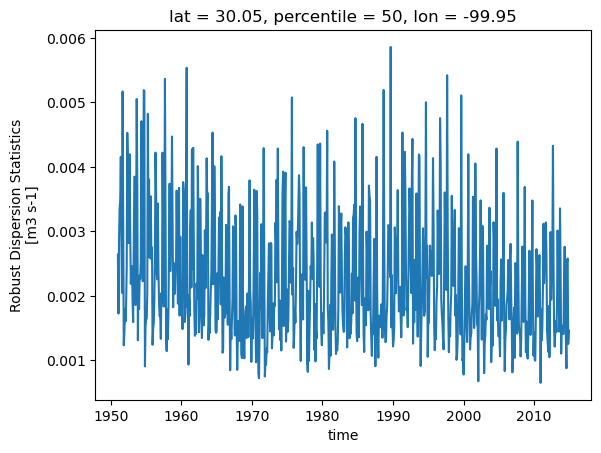

In [15]:
point.sel(percentile=50).plot()